# ASFL-IoT Experiments: Kaggle-Ready Updated Notebook

This notebook reproduces the paper-facing ASFL-IoT experiments with the corrected configuration:

- calibrated risk-coupled DATT trust simulation,
- sync-blocking vs AsyncFLP under packet loss,
- BRAE under Byzantine attacks,
- fixed DP vs SADP sweep,
- PFL evaluated using per-client personalized heads,
- ablation, synthetic IoT validation, runtime logging, confidence intervals, and final paper key results export.

In [1]:
import os, json, math, random, time, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits, make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
OUT_DIR = "/kaggle/working/asfl_iot_results"
FIG_DIR = f"{OUT_DIR}/figures"
os.makedirs(FIG_DIR, exist_ok=True)

print("Device:", DEVICE)
print("Output directory:", OUT_DIR)

Device: cuda
Output directory: /kaggle/working/asfl_iot_results


In [2]:
CONFIG = {
    "seeds": [1, 7, 21, 42, 100],
    "num_clients": 10,
    "rounds": 20,
    "local_epochs": 2,
    "batch_size": 32,
    "lr": 0.02,
    "dirichlet_alpha": 0.5,
    "max_train_samples": 3000,
    "trust_threshold": 0.55,
    "datt_k": 1.5,
    "datt_rho": 0.3,
    "staleness_lambda": 0.3,
    "byzantine_fraction": 0.3,
    "dp_epsilon": 0.7,
    "dp_delta": 1e-5,
    "sync_quorum": 0.8,
    "fixed_dp_noise": 0.004,
    "sadp_noise": 0.008,
    "datt_drift_penalty": 0.6,
    "datt_anomaly_penalty": 0.50,
    "datt_iqr_scale": 0.50,
}

with open(f"{OUT_DIR}/config.json", "w") as f:
    json.dump(CONFIG, f, indent=2)

CONFIG

{'seeds': [1, 7, 21, 42, 100],
 'num_clients': 10,
 'rounds': 20,
 'local_epochs': 2,
 'batch_size': 32,
 'lr': 0.02,
 'dirichlet_alpha': 0.5,
 'max_train_samples': 3000,
 'trust_threshold': 0.55,
 'datt_k': 1.5,
 'datt_rho': 0.3,
 'staleness_lambda': 0.3,
 'byzantine_fraction': 0.3,
 'dp_epsilon': 0.7,
 'dp_delta': 1e-05,
 'sync_quorum': 0.8,
 'fixed_dp_noise': 0.004,
 'sadp_noise': 0.008,
 'datt_drift_penalty': 0.6,
 'datt_anomaly_penalty': 0.5,
 'datt_iqr_scale': 0.5}

In [3]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

print("Seed helper ready.")

Seed helper ready.


In [4]:
def load_digits_dataset(seed=42):
    data = load_digits()
    X = data.data.astype(np.float32)
    y = data.target.astype(np.int64)
    X = StandardScaler().fit_transform(X).astype(np.float32)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.25, random_state=seed, stratify=y
    )
    return X_train, X_test, y_train, y_test, 10, X.shape[1]


def load_synthetic_iot(seed=42):
    X, y = make_classification(
        n_samples=4000,
        n_features=30,
        n_informative=16,
        n_redundant=6,
        n_classes=4,
        n_clusters_per_class=1,
        weights=[0.94, 0.04, 0.015, 0.005],
        class_sep=1.6,
        flip_y=0.01,
        random_state=seed,
    )
    X = StandardScaler().fit_transform(X).astype(np.float32)
    y = y.astype(np.int64)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.25, random_state=seed, stratify=y
    )
    return X_train, X_test, y_train, y_test, 4, X.shape[1]

Xtr, Xte, ytr, yte, nc, dim = load_digits_dataset(42)
print("Digits:", Xtr.shape, Xte.shape, "classes:", nc, "dim:", dim)
Xtr, Xte, ytr, yte, nc, dim = load_synthetic_iot(42)
print("Synthetic IoT:", Xtr.shape, Xte.shape, "classes:", nc, "dim:", dim)

Digits: (1347, 64) (450, 64) classes: 10 dim: 64
Synthetic IoT: (3000, 30) (1000, 30) classes: 4 dim: 30


In [5]:
def dirichlet_partition(y, num_clients=10, alpha=0.5, seed=42, min_size=5):
    rng = np.random.default_rng(seed)
    y = np.asarray(y)
    classes = np.unique(y)

    for _ in range(200):
        parts = [[] for _ in range(num_clients)]
        for cls in classes:
            idx = np.where(y == cls)[0]
            rng.shuffle(idx)
            props = rng.dirichlet(np.repeat(alpha, num_clients))
            cuts = (np.cumsum(props)[:-1] * len(idx)).astype(int)
            splits = np.split(idx, cuts)
            for cid, split in enumerate(splits):
                parts[cid].extend(split.tolist())
        sizes = [len(p) for p in parts]
        if min(sizes) >= min_size:
            return [np.array(p, dtype=np.int64) for p in parts]

    return [np.array(p, dtype=np.int64) for p in parts]

parts = dirichlet_partition(load_digits_dataset(42)[2], CONFIG["num_clients"], CONFIG["dirichlet_alpha"], 42)
print("Client sizes:", [len(p) for p in parts])
print("Min/max:", min(len(p) for p in parts), max(len(p) for p in parts))

Client sizes: [145, 98, 61, 161, 122, 76, 213, 186, 103, 182]
Min/max: 61 213


In [6]:
class SmallMLP(nn.Module):
    def __init__(self, input_dim, num_classes, hidden=96):
        super().__init__()
        self.body = nn.Sequential(
            nn.Linear(input_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden // 2),
            nn.ReLU(),
        )
        self.head = nn.Linear(hidden // 2, num_classes)

    def forward(self, x):
        return self.head(self.body(x))


def get_params(model):
    return {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}


def set_params(model, params, body_only=False):
    sd = model.state_dict()
    for k, v in params.items():
        if body_only and k.startswith("head."):
            continue
        if k in sd:
            sd[k] = v.to(DEVICE).clone()
    model.load_state_dict(sd)


def average_params(param_list, weights=None, body_only=False):
    if weights is None:
        weights = np.ones(len(param_list), dtype=np.float64) / len(param_list)
    weights = np.asarray(weights, dtype=np.float64)
    weights = weights / weights.sum()
    out = {}
    for k in param_list[0].keys():
        if body_only and k.startswith("head."):
            continue
        acc = None
        for w, params in zip(weights, param_list):
            val = params[k].float() * float(w)
            acc = val if acc is None else acc + val
        out[k] = acc.cpu()
    return out

print("Model helpers ready.")

Model helpers ready.


In [7]:
def make_loader(X, y, batch_size=32, shuffle=True):
    ds = TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y, dtype=torch.long),
    )
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)


def train_local(model, X, y, epochs=1, lr=0.02, batch_size=32):
    model.train()
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    loss_fn = nn.CrossEntropyLoss()
    loader = make_loader(X, y, batch_size, shuffle=True)
    for _ in range(epochs):
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            opt.step()


def evaluate(model, X, y):
    model.eval()
    preds = []
    loader = make_loader(X, y, batch_size=256, shuffle=False)
    with torch.no_grad():
        for xb, _ in loader:
            logits = model(xb.to(DEVICE))
            preds.extend(logits.argmax(1).cpu().numpy().tolist())
    return {
        "accuracy": accuracy_score(y, preds),
        "macro_f1": f1_score(y, preds, average="macro", zero_division=0),
    }

print("Training helpers ready.")

Training helpers ready.


In [8]:
def compute_datt_threshold(trust_scores, anomaly_scores=None, prev_theta=0.55, prev_mu=0.55,
                           drift_penalty=None, anomaly_penalty=None, iqr_scale=None):
    trust_scores = np.asarray(trust_scores, dtype=np.float64)
    if anomaly_scores is None:
        anomaly_scores = np.zeros_like(trust_scores)
    anomaly_scores = np.asarray(anomaly_scores, dtype=np.float64)

    drift_penalty = CONFIG["datt_drift_penalty"] if drift_penalty is None else drift_penalty
    anomaly_penalty = CONFIG["datt_anomaly_penalty"] if anomaly_penalty is None else anomaly_penalty
    iqr_scale = CONFIG["datt_iqr_scale"] if iqr_scale is None else iqr_scale

    q1, q3 = np.percentile(trust_scores, [25, 75])
    iqr = max(q3 - q1, 1e-6)
    mu = trust_scores.mean()
    volatility = iqr_scale * iqr
    drift = max(0.0, prev_mu - mu)
    risk_adjusted = trust_scores - anomaly_penalty * anomaly_scores
    theta = np.median(risk_adjusted) - volatility + drift_penalty * drift + CONFIG["datt_rho"] * (prev_theta - prev_mu)
    theta = float(np.clip(theta, 0.15, 0.85))
    return theta, mu


def static_trust_filter(trust_scores, threshold=0.55):
    return [i for i, t in enumerate(trust_scores) if t >= threshold]


def datt_filter(trust_scores, anomaly_scores=None, prev_theta=0.55, prev_mu=0.55):
    theta, mu = compute_datt_threshold(trust_scores, anomaly_scores, prev_theta, prev_mu)
    if anomaly_scores is None:
        risk_adjusted = np.asarray(trust_scores)
    else:
        risk_adjusted = np.asarray(trust_scores) - CONFIG["datt_anomaly_penalty"] * np.asarray(anomaly_scores)
    return [i for i, s in enumerate(risk_adjusted) if s >= theta], theta, mu


def flatten_params(params, body_only=False):
    vecs = []
    for k, v in params.items():
        if body_only and k.startswith("head."):
            continue
        vecs.append(v.reshape(-1).float())
    return torch.cat(vecs)


def cosine(a, b):
    return float(torch.dot(a, b) / (torch.norm(a) * torch.norm(b) + 1e-12))


def brae_filter(global_params, client_params, mad_beta=3.0, cosine_min=-0.3):
    if len(client_params) <= 2:
        return list(range(len(client_params))), {"detected": 0}
    vecs = [flatten_params(p) for p in client_params]
    stack = torch.stack(vecs)
    median_vec = stack.median(dim=0).values
    distances = torch.norm(stack - median_vec, dim=1).numpy()
    med = np.median(distances)
    mad = np.median(np.abs(distances - med)) + 1e-12
    keep_mad = distances <= med + mad_beta * mad
    global_vec = flatten_params(global_params)
    keep_cos = np.array([cosine(v, global_vec) >= cosine_min for v in vecs])
    keep = np.where(keep_mad & keep_cos)[0].tolist()
    return keep, {"detected": len(client_params) - len(keep)}


def add_fixed_dp(params, noise_scale=None):
    noise_scale = CONFIG["fixed_dp_noise"] if noise_scale is None else noise_scale
    return {k: v + torch.randn_like(v) * noise_scale for k, v in params.items()}


def add_sadp(params, base_noise=None):
    base_noise = CONFIG["sadp_noise"] if base_noise is None else base_noise
    noisy = {}
    for k, v in params.items():
        if k.startswith("head."):
            scale = base_noise * 0.60
        elif "weight" in k:
            scale = base_noise * 0.80
        else:
            scale = base_noise * 0.35
        noisy[k] = v + torch.randn_like(v) * scale
    return noisy


def make_byzantine(params, attack="sign_flip"):
    attacked = {}
    for k, v in params.items():
        if attack == "sign_flip":
            attacked[k] = -3.0 * v
        elif attack == "gaussian":
            attacked[k] = v + torch.randn_like(v) * 5.0
        elif attack == "model_replacement":
            attacked[k] = v * 10.0
        else:
            attacked[k] = v
    return attacked

print("ASFL-IoT module helpers ready.")

ASFL-IoT module helpers ready.


In [10]:
def run_federated(
    dataset_name="digits",
    method="fedavg",
    seed=42,
    alpha=0.5,
    rounds=None,
    hidden=96,
    num_clients=None,
    packet_loss=0.0,
    byz_frac=0.0,
    attack="sign_flip",
    use_static_trust=True,
    use_datt=False,
    use_async=False,
    sync_blocking=False,
    use_brae=False,
    dp_mode="none",
    use_pfl=False,
    return_state=False,
):
    set_seed(seed)
    rounds = CONFIG["rounds"] if rounds is None else rounds
    num_clients = CONFIG["num_clients"] if num_clients is None else num_clients

    if dataset_name == "digits":
        X_train, X_test, y_train, y_test, num_classes, input_dim = load_digits_dataset(seed)
    elif dataset_name == "iot":
        X_train, X_test, y_train, y_test, num_classes, input_dim = load_synthetic_iot(seed)
    else:
        raise ValueError("Unknown dataset")

    parts = dirichlet_partition(y_train, num_clients, alpha, seed)
    global_model = SmallMLP(
       input_dim, num_classes, hidden=hidden
    ).to(DEVICE)
    global_params = get_params(global_model)
    client_heads = [None] * num_clients
    prev_theta, prev_mu = CONFIG["trust_threshold"], CONFIG["trust_threshold"]
    staleness = np.zeros(num_clients)
    history = []
    skipped_rounds = 0

    byz_clients = set(np.random.choice(num_clients, int(num_clients * byz_frac), replace=False))

    start_time = time.time()
    for r in range(rounds):
        trust_scores = np.random.normal(0.72, 0.08, size=num_clients)
        anomaly_scores = np.random.beta(1.2, 10.0, size=num_clients) * 0.35
        if byz_frac > 0:
            for cid in byz_clients:
                trust_scores[cid] = np.random.normal(0.58 + 0.005 * r, 0.06)
                anomaly_scores[cid] = np.random.beta(7.0, 2.0) * 0.65 + 0.25
        trust_scores = np.clip(trust_scores, 0, 1)
        anomaly_scores = np.clip(anomaly_scores, 0, 1)

        if use_datt:
            admitted, prev_theta, prev_mu = datt_filter(trust_scores, anomaly_scores, prev_theta, prev_mu)
        elif use_static_trust:
            admitted = static_trust_filter(trust_scores, CONFIG["trust_threshold"])
        else:
            admitted = list(range(num_clients))

        online = [cid for cid in admitted if np.random.rand() >= packet_loss]

        if sync_blocking:
            required = int(math.ceil(CONFIG["sync_quorum"] * num_clients))
            if len(online) < required:
                skipped_rounds += 1
                staleness += 1
                metrics = evaluate(global_model, X_test, y_test)
                metrics.update({
                    "round": r + 1, "seed": seed, "dataset": dataset_name, "method": method,
                    "online_clients": len(online), "used_clients": 0, "detected": 0,
                    "packet_loss": packet_loss, "byz_frac": byz_frac, "alpha": alpha,
                    "skipped": 1, "elapsed_sec": time.time() - start_time,
                })
                history.append(metrics)
                continue

        if len(online) == 0:
            skipped_rounds += 1
            staleness += 1
            continue

        client_params, client_ids = [], []
        for cid in online:
            idx = parts[cid]
            if len(idx) == 0:
                continue
            model = SmallMLP(input_dim, num_classes,hidden=hidden).to(DEVICE)
            if use_pfl and client_heads[cid] is not None:
                set_params(model, global_params, body_only=True)
                sd = model.state_dict()
                for k, v in client_heads[cid].items():
                    sd[k] = v.to(DEVICE)
                model.load_state_dict(sd)
            else:
                set_params(model, global_params)

            train_local(model, X_train[idx], y_train[idx], epochs=CONFIG["local_epochs"], lr=CONFIG["lr"], batch_size=CONFIG["batch_size"])
            params = get_params(model)
            if use_pfl:
                client_heads[cid] = {k: v for k, v in params.items() if k.startswith("head.")}
            if cid in byz_clients:
                params = make_byzantine(params, attack)
            client_params.append(params)
            client_ids.append(cid)

        if len(client_params) == 0:
            skipped_rounds += 1
            continue

        detected = 0
        if use_brae:
            keep_idx, info = brae_filter(global_params, client_params)
            detected = info.get("detected", 0)
            client_params = [client_params[i] for i in keep_idx]
            client_ids = [client_ids[i] for i in keep_idx]

        if len(client_params) == 0:
            skipped_rounds += 1
            continue

        if use_async:
            weights = np.array([math.exp(-CONFIG["staleness_lambda"] * staleness[cid]) for cid in client_ids])
            weights = weights / weights.sum()
        else:
            weights = None

        new_global = average_params(client_params, weights=weights, body_only=use_pfl)
        if use_pfl:
            merged = global_params.copy()
            merged.update(new_global)
            global_params = merged
        else:
            global_params = new_global

        if dp_mode == "fixed_dp":
            global_params = add_fixed_dp(global_params)
        elif dp_mode == "sadp":
            global_params = add_sadp(global_params)

        set_params(global_model, global_params, body_only=False)
        staleness += 1
        for cid in client_ids:
            staleness[cid] = 0

        metrics = evaluate(global_model, X_test, y_test)
        metrics.update({
            "round": r + 1, "seed": seed, "dataset": dataset_name, "method": method,
            "online_clients": len(online), "used_clients": len(client_params), "detected": detected,
            "packet_loss": packet_loss, "byz_frac": byz_frac, "alpha": alpha,
            "skipped": 0, "elapsed_sec": time.time() - start_time,
        })
        history.append(metrics)

    if len(history) == 0:
        history = [{"seed": seed, "dataset": dataset_name, "method": method, "round": 0, "accuracy": np.nan, "macro_f1": np.nan,
                    "online_clients": 0, "used_clients": 0, "detected": 0, "packet_loss": packet_loss, "byz_frac": byz_frac,
                    "alpha": alpha, "skipped": skipped_rounds, "elapsed_sec": time.time() - start_time}]

    df = pd.DataFrame(history)
    if return_state:
        state = dict(global_params=global_params, client_heads=client_heads, parts=parts, data=(X_train, X_test, y_train, y_test, num_classes, input_dim))
        return df, state
    return df

print("Main FL runner ready.")

Main FL runner ready.


In [11]:
def final_row(df):
    return df.tail(1).copy()

sanity = run_federated(dataset_name="digits", method="fedavg_sanity", seed=42, rounds=3, packet_loss=0.0)
display(sanity)

,accuracy,macro_f1,round,seed,dataset,method,online_clients,used_clients,detected,packet_loss,byz_frac,alpha,skipped,elapsed_sec
0,0.237778,0.168822,1,42,digits,fedavg_sanity,9,9,0,0.0,0.0,0.5,0,3.667218
1,0.366667,0.277226,2,42,digits,fedavg_sanity,10,10,0,0.0,0.0,0.5,0,3.828923
2,0.486667,0.389898,3,42,digits,fedavg_sanity,10,10,0,0.0,0.0,0.5,0,3.985633


In [12]:
# Scalability and model-capacity evaluation
SCALABILITY_CLIENTS = [10, 25, 50]
SCALABILITY_ROUNDS = [20, 50]
SCALABILITY_SEEDS = [1, 7, 21, 42, 100]
SCALABILITY_DATASETS = ["digits", "iot"]

methods = {
    "fedavg": dict(
        use_static_trust=False,
        use_datt=False,
        use_async=False,
        use_brae=False,
        dp_mode="none",
        use_pfl=False,
    ),
    "asfl_core": dict(
        use_static_trust=True,
        use_datt=True,
        use_async=True,
        use_brae=True,
        dp_mode="sadp",
        use_pfl=False,
    ),
}

# The hidden=384 configuration tests a substantially larger MLP.
experiment_grid = [
    {
        "clients": clients,
        "rounds": rounds,
        "hidden": 96,
        "experiment": "scalability",
    }
    for clients in SCALABILITY_CLIENTS
    for rounds in SCALABILITY_ROUNDS
]

experiment_grid.append({
    "clients": 25,
    "rounds": 50,
    "hidden": 384,
    "experiment": "larger_model",
})

generalization_rows = []
start = time.time()

for dataset_name in SCALABILITY_DATASETS:
    for setting in experiment_grid:
        for seed in SCALABILITY_SEEDS:
            for method, kwargs in methods.items():
                df = run_federated(
                    dataset_name=dataset_name,
                    method=method,
                    seed=seed,
                    alpha=0.5,
                    rounds=setting["rounds"],
                    num_clients=setting["clients"],
                    hidden=setting["hidden"],
                    packet_loss=0.10,
                    byz_frac=0.10,
                    attack="sign_flip",
                    **kwargs,
                )

                row = final_row(df).iloc[0].to_dict()
                row.update(setting)
                generalization_rows.append(row)

generalization_df = pd.DataFrame(generalization_rows)
generalization_df.to_csv(
    f"{OUT_DIR}/generalization_raw.csv", index=False
)

generalization_summary = (
    generalization_df
    .groupby([
        "dataset", "experiment", "clients",
        "rounds", "hidden", "method"
    ])
    .agg(
        accuracy_mean=("accuracy", "mean"),
        accuracy_std=("accuracy", "std"),
        macro_f1_mean=("macro_f1", "mean"),
        macro_f1_std=("macro_f1", "std"),
        used_clients_mean=("used_clients", "mean"),
        elapsed_sec_mean=("elapsed_sec", "mean"),
    )
    .reset_index()
)

generalization_summary.to_csv(
    f"{OUT_DIR}/generalization_summary.csv", index=False
)

print("Generalization experiment seconds:",
      round(time.time() - start, 2))

display(generalization_summary)

Generalization experiment seconds: 1329.57


,dataset,experiment,clients,rounds,hidden,method,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,used_clients_mean,elapsed_sec_mean
0,digits,larger_model,25,50,384,asfl_core,0.942222,0.006285,0.942159,0.006288,16.8,10.437323
1,digits,larger_model,25,50,384,fedavg,0.099111,0.002534,0.018034,0.000420,21.4,11.100849
2,digits,scalability,10,20,96,asfl_core,0.885333,0.096361,0.877494,0.114155,6.6,2.358797
3,digits,scalability,10,20,96,fedavg,0.100444,0.002897,0.018254,0.000480,8.8,3.035338
4,digits,scalability,10,50,96,asfl_core,0.948000,0.023019,0.947844,0.022997,5.8,6.094259
5,digits,scalability,10,50,96,fedavg,0.100444,0.002897,0.018254,0.000480,9.2,7.416872
6,digits,scalability,25,20,96,asfl_core,0.628444,0.074823,0.587363,0.080385,14.8,3.280718
7,digits,scalability,25,20,96,fedavg,0.100889,0.001217,0.018328,0.000201,22.2,3.856618
8,digits,scalability,25,50,96,asfl_core,0.887556,0.021522,0.883756,0.021873,16.0,7.868177
9,digits,scalability,25,50,96,fedavg,0.099111,0.002534,0.018034,0.000420,21.4,9.531849


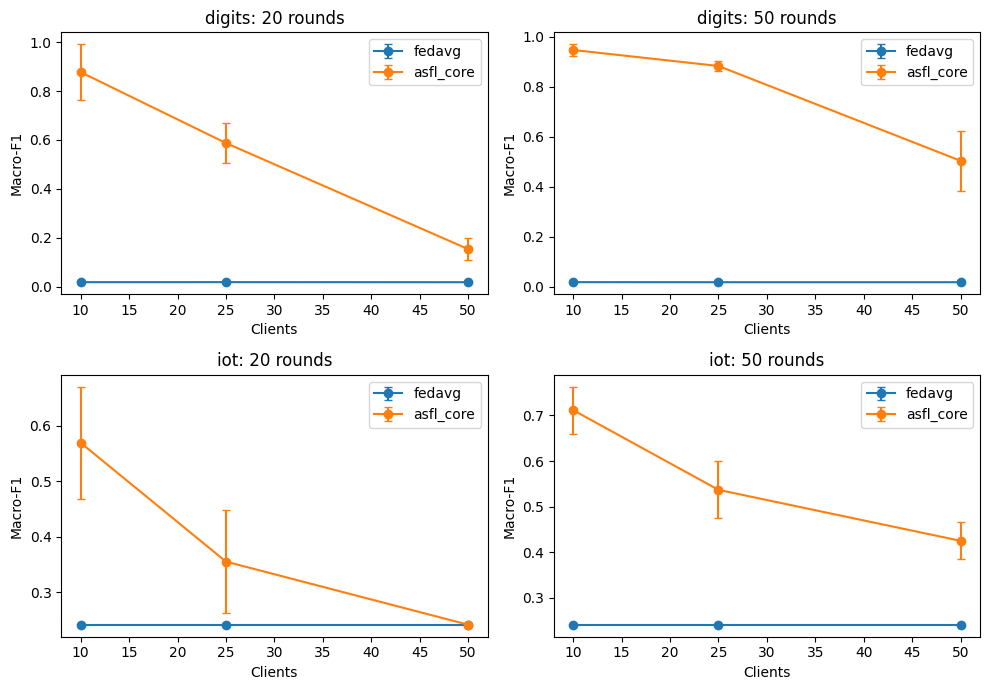

In [13]:
scale_only = generalization_summary[
    generalization_summary["experiment"] == "scalability"
]

fig, axes = plt.subplots(2, 2, figsize=(10, 7))

for row, dataset_name in enumerate(["digits", "iot"]):
    for col, rounds in enumerate([20, 50]):
        ax = axes[row, col]
        sub = scale_only[
            (scale_only["dataset"] == dataset_name) &
            (scale_only["rounds"] == rounds)
        ]

        for method in ["fedavg", "asfl_core"]:
            m = sub[sub["method"] == method]
            ax.errorbar(
                m["clients"],
                m["macro_f1_mean"],
                yerr=m["macro_f1_std"],
                marker="o",
                capsize=3,
                label=method,
            )

        ax.set_title(f"{dataset_name}: {rounds} rounds")
        ax.set_xlabel("Clients")
        ax.set_ylabel("Macro-F1")
        ax.legend()

fig.tight_layout()
fig.savefig(
    f"{FIG_DIR}/scalability_macro_f1.pdf",
    bbox_inches="tight"
)
plt.show()

In [14]:
def run_trust_datt_calibrated():
    rows = []
    for seed in CONFIG["seeds"]:
        for cv in [0.1, 0.3, 0.5]:
            set_seed(seed)
            n = 1000
            rounds = 50
            adv_frac = 0.20
            adv_n = int(n * adv_frac)
            adv_idx = set(np.random.choice(n, adv_n, replace=False))
            benign_idx = set(range(n)) - adv_idx

            for mode in ["static", "datt"]:
                prev_theta, prev_mu = 0.55, 0.55
                fnrs, fprs = [], []
                for r in range(rounds):
                    trust = np.random.normal(0.72, cv * 0.12, size=n)
                    anomaly = np.random.beta(1.1, 11.0, size=n) * 0.30
                    for i in adv_idx:
                        trust[i] = np.random.normal(0.45 + 0.008 * r, cv * 0.10)
                        anomaly[i] = np.random.beta(9.0, 1.7) * 0.72 + 0.20
                    trust = np.clip(trust, 0, 1)
                    anomaly = np.clip(anomaly, 0, 1)

                    if mode == "static":
                        admitted = set(static_trust_filter(trust, 0.55))
                    else:
                        admitted_list, prev_theta, prev_mu = datt_filter(trust, anomaly, prev_theta, prev_mu)
                        admitted = set(admitted_list)

                    adv_admitted = len(admitted.intersection(adv_idx))
                    benign_rejected = len(benign_idx - admitted)
                    fnrs.append(adv_admitted / max(1, adv_n))
                    fprs.append(benign_rejected / max(1, len(benign_idx)))

                rows.append({
                    "seed": seed, "cv": cv, "method": mode,
                    "fnr": np.mean(fnrs[-10:]), "fpr": np.mean(fprs[-10:]),
                    "drift_penalty": CONFIG["datt_drift_penalty"],
                    "anomaly_penalty": CONFIG["datt_anomaly_penalty"],
                    "iqr_scale": CONFIG["datt_iqr_scale"],
                })
    return pd.DataFrame(rows)

trust_df = run_trust_datt_calibrated()
trust_df.to_csv(f"{OUT_DIR}/trust_drift_results.csv", index=False)
trust_summary = trust_df.groupby(["cv", "method"])[["fnr", "fpr"]].agg(["mean", "std"])
display(trust_summary)

fnr                 fpr          
              mean       std      mean       std
cv  method                                      
0.1 datt    0.0000  0.000000  0.031075  0.000808
    static  1.0000  0.000000  0.000000  0.000000
0.3 datt    0.0001  0.000224  0.025625  0.001196
    static  1.0000  0.000000  0.000000  0.000000
0.5 datt    0.0044  0.001746  0.042750  0.001930
    static  1.0000  0.000000  0.002050  0.000429

In [15]:
async_results = []
start = time.time()
for seed in CONFIG["seeds"]:
    for packet_loss in [0.0, 0.1, 0.2, 0.3, 0.4]:
        for method, kwargs in [
            ("sync_blocking", dict(sync_blocking=True, use_async=False)),
            ("asyncflp", dict(sync_blocking=False, use_async=True)),
        ]:
            df = run_federated(
                dataset_name="digits", method=method, seed=seed, alpha=0.5,
                packet_loss=packet_loss, **kwargs
            )
            async_results.append(final_row(df))
async_df = pd.concat(async_results, ignore_index=True)
async_df.to_csv(f"{OUT_DIR}/async_results.csv", index=False)
print("Async experiment seconds:", round(time.time() - start, 2))
display(async_df.groupby(["packet_loss", "method"])[["accuracy", "macro_f1", "used_clients", "skipped"]].agg(["mean", "std"]))

Async experiment seconds: 110.06


accuracy            macro_f1            \
                               mean       std      mean       std   
packet_loss method                                                  
0.0         asyncflp       0.932889  0.014690  0.932643  0.014790   
            sync_blocking  0.933333  0.014657  0.933114  0.014755   
0.1         asyncflp       0.932889  0.014002  0.932678  0.014277   
            sync_blocking  0.922222  0.010304  0.921640  0.010916   
0.2         asyncflp       0.930222  0.014791  0.929961  0.014781   
            sync_blocking  0.870667  0.039765  0.866856  0.042392   
0.3         asyncflp       0.928889  0.017213  0.928336  0.017802   
            sync_blocking  0.770222  0.087610  0.744053  0.118104   
0.4         asyncflp       0.923556  0.015761  0.922635  0.017214   
            sync_blocking  0.472889  0.259322  0.416290  0.281004   

                          used_clients           skipped            
                                  mean       std    mean       std  
packet_loss method                                                  
0.0         asyncflp              10.0  0.000000     0.0  0.000000  
            sync_blocking         10.0  0.000000     0.0  0.000000  
0.1         asyncflp               9.2  0.836660     0.0  0.000000  
            sync_blocking          9.2  0.836660     0.0  0.000000  
0.2         asyncflp               8.0  1.414214     0.0  0.000000  
            sync_blocking          3.8  5.215362     0.6  0.547723  
0.3         asyncflp               6.8  2.049390     0.0  0.000000  
            sync_blocking          3.6  4.929503     0.6  0.547723  
0.4         asyncflp               6.0  2.345208     0.0  0.000000  
            sync_blocking          3.4  4.669047     0.6  0.547723

In [16]:
byz_results = []
start = time.time()
for seed in CONFIG["seeds"]:
    for byz_frac in [0.1, 0.2, 0.3]:
        for attack in ["sign_flip", "gaussian", "model_replacement"]:
            for method, use_brae in [("no_defense", False), ("brae", True)]:
                df = run_federated(
                    dataset_name="digits", method=f"{method}_{attack}", seed=seed, alpha=0.5,
                    byz_frac=byz_frac, attack=attack, use_brae=use_brae
                )
                byz_results.append(final_row(df))
byz_df = pd.concat(byz_results, ignore_index=True)
byz_df.to_csv(f"{OUT_DIR}/byzantine_results.csv", index=False)
print("Byzantine experiment seconds:", round(time.time() - start, 2))
display(byz_df.groupby(["byz_frac", "method"])[["accuracy", "macro_f1", "detected"]].agg(["mean", "std"]))

Byzantine experiment seconds: 288.28


accuracy            macro_f1            \
                                           mean       std      mean       std   
byz_frac method                                                                 
0.1      brae_gaussian                 0.892000  0.073377  0.884613  0.088244   
         brae_model_replacement        0.890667  0.098400  0.884153  0.112014   
         brae_sign_flip                0.900000  0.077667  0.892827  0.092716   
         no_defense_gaussian           0.784000  0.026685  0.776410  0.028205   
         no_defense_model_replacement  0.099556  0.002434  0.018115  0.000414   
         no_defense_sign_flip          0.100000  0.002722  0.018181  0.000451   
0.2      brae_gaussian                 0.919111  0.034520  0.917620  0.037373   
         brae_model_replacement        0.919556  0.035465  0.918024  0.038448   
         brae_sign_flip                0.919556  0.035465  0.918024  0.038448   
         no_defense_gaussian           0.525778  0.232934  0.505120  0.244953   
         no_defense_model_replacement  0.100889  0.001217  0.018343  0.000223   
         no_defense_sign_flip          0.099111  0.002534  0.018034  0.000420   
0.3      brae_gaussian                 0.896889  0.034376  0.890095  0.041184   
         brae_model_replacement        0.866222  0.052030  0.852492  0.064177   
         brae_sign_flip                0.896000  0.033051  0.889404  0.039762   
         no_defense_gaussian           0.442222  0.250516  0.428459  0.267030   
         no_defense_model_replacement  0.100889  0.004037  0.020586  0.005578   
         no_defense_sign_flip          0.098667  0.001988  0.017961  0.000330   

                                      detected            
                                          mean       std  
byz_frac method                                           
0.1      brae_gaussian                     1.6  0.894427  
         brae_model_replacement            1.6  1.341641  
         brae_sign_flip                    1.4  0.894427  
         no_defense_gaussian               0.0  0.000000  
         no_defense_model_replacement      0.0  0.000000  
         no_defense_sign_flip              0.0  0.000000  
0.2      brae_gaussian                     2.0  0.000000  
         brae_model_replacement            2.0  0.000000  
         brae_sign_flip                    2.0  0.000000  
         no_defense_gaussian               0.0  0.000000  
         no_defense_model_replacement      0.0  0.000000  
         no_defense_sign_flip              0.0  0.000000  
0.3      brae_gaussian                     2.8  0.447214  
         brae_model_replacement            3.0  0.000000  
         brae_sign_flip                    2.8  0.447214  
         no_defense_gaussian               0.0  0.000000  
         no_defense_model_replacement      0.0  0.000000  
         no_defense_sign_flip              0.0  0.000000

In [17]:
dp_results = []
start = time.time()
for seed in CONFIG["seeds"]:
    for method, dp_mode in [("none", "none"), ("fixed_dp", "fixed_dp"), ("sadp", "sadp")]:
        df = run_federated(
            dataset_name="digits", method=method, seed=seed, alpha=0.5,
            packet_loss=0.0, dp_mode=dp_mode
        )
        dp_results.append(final_row(df))
dp_df = pd.concat(dp_results, ignore_index=True)
dp_df.to_csv(f"{OUT_DIR}/privacy_results.csv", index=False)
print("Privacy experiment seconds:", round(time.time() - start, 2))
display(dp_df.groupby("method")[["accuracy", "macro_f1"]].agg(["mean", "std"]))

Privacy experiment seconds: 47.9


accuracy            macro_f1          
              mean       std      mean       std
method                                          
fixed_dp  0.934222  0.013481  0.934178  0.013392
none      0.933333  0.014657  0.933099  0.014755
sadp      0.932000  0.015524  0.932028  0.015418

In [18]:
def evaluate_personalized_clients(state, use_pfl, dataset_name="digits"):
    global_params = state["global_params"]
    client_heads = state["client_heads"]
    parts = state["parts"]
    X_train, X_test, y_train, y_test, num_classes, input_dim = state["data"]
    client_metrics = []

    for cid, idx in enumerate(parts):
        if len(idx) < 5:
            continue
        Xc, yc = X_train[idx], y_train[idx]
        if len(np.unique(yc)) < 2:
            continue
        tr_idx, te_idx = train_test_split(
            np.arange(len(yc)), test_size=0.35, random_state=cid + 123,
            stratify=yc if min(np.bincount(yc)) >= 2 else None
        )
        model = SmallMLP(input_dim, num_classes).to(DEVICE)
        set_params(model, global_params)
        if use_pfl and client_heads[cid] is not None:
            sd = model.state_dict()
            for k, v in client_heads[cid].items():
                sd[k] = v.to(DEVICE)
            model.load_state_dict(sd)
        metrics = evaluate(model, Xc[te_idx], yc[te_idx])
        metrics.update({"client": cid, "client_size": len(idx)})
        client_metrics.append(metrics)

    client_df = pd.DataFrame(client_metrics)
    return {
        "mean_client_accuracy": client_df["accuracy"].mean(),
        "worst_client_accuracy": client_df["accuracy"].min(),
        "client_accuracy_std": client_df["accuracy"].std(),
        "mean_client_macro_f1": client_df["macro_f1"].mean(),
    }, client_df

pfl_results = []
pfl_client_rows = []
start = time.time()
for seed in CONFIG["seeds"]:
    for alpha in [0.1, 0.3, 0.5, 1.0, 100.0]:
        for method, use_pfl in [("fedavg", False), ("pfl", True)]:
            df, state = run_federated(
                dataset_name="digits", method=method, seed=seed, alpha=alpha,
                use_pfl=use_pfl, return_state=True
            )
            summary, clients = evaluate_personalized_clients(state, use_pfl)
            row = {"seed": seed, "alpha": alpha, "method": method, **summary}
            pfl_results.append(row)
            clients["seed"] = seed
            clients["alpha"] = alpha
            clients["method"] = method
            pfl_client_rows.append(clients)

pfl_df = pd.DataFrame(pfl_results)
pfl_clients_df = pd.concat(pfl_client_rows, ignore_index=True)
pfl_df.to_csv(f"{OUT_DIR}/pfl_results.csv", index=False)
pfl_clients_df.to_csv(f"{OUT_DIR}/pfl_client_level_results.csv", index=False)
print("PFL experiment seconds:", round(time.time() - start, 2))
display(pfl_df.groupby(["alpha", "method"])[["mean_client_accuracy", "worst_client_accuracy", "client_accuracy_std", "mean_client_macro_f1"]].agg(["mean", "std"]))

PFL experiment seconds: 165.99


mean_client_accuracy           worst_client_accuracy            \
                             mean       std                  mean       std   
alpha method                                                                  
0.1   fedavg             0.926191  0.017718              0.751380  0.130682   
      pfl                0.966316  0.016184              0.882845  0.060393   
0.3   fedavg             0.949999  0.010355              0.872734  0.034028   
      pfl                0.963620  0.007924              0.895212  0.035623   
0.5   fedavg             0.945570  0.016681              0.851352  0.043428   
      pfl                0.959167  0.007008              0.911734  0.029514   
1.0   fedavg             0.962651  0.006621              0.915124  0.014754   
      pfl                0.962544  0.010606              0.907163  0.036468   
100.0 fedavg             0.956590  0.006397              0.907552  0.023172   
      pfl                0.971725  0.006699              0.928242  0.021919   

             client_accuracy_std           mean_client_macro_f1            
                            mean       std                 mean       std  
alpha method                                                               
0.1   fedavg            0.076265  0.032118             0.717850  0.032994  
      pfl               0.040990  0.018856             0.853574  0.032423  
0.3   fedavg            0.038096  0.010210             0.830404  0.047688  
      pfl               0.036026  0.010954             0.872214  0.033312  
0.5   fedavg            0.044283  0.013256             0.871508  0.041361  
      pfl               0.026259  0.006972             0.863167  0.032046  
1.0   fedavg            0.026725  0.004518             0.936046  0.010784  
      pfl               0.027513  0.011116             0.904681  0.032303  
100.0 fedavg            0.028479  0.005332             0.954976  0.006372  
      pfl               0.024852  0.007155             0.970399  0.006984

In [19]:
ablations = {
    "full_asfl": dict(use_datt=True, use_async=True, sync_blocking=False, use_brae=True, dp_mode="sadp", use_pfl=True),
    "no_datt": dict(use_datt=False, use_async=True, sync_blocking=False, use_brae=True, dp_mode="sadp", use_pfl=True),
    "no_async": dict(use_datt=True, use_async=False, sync_blocking=True, use_brae=True, dp_mode="sadp", use_pfl=True),
    "no_brae": dict(use_datt=True, use_async=True, sync_blocking=False, use_brae=False, dp_mode="sadp", use_pfl=True),
    "no_sadp": dict(use_datt=True, use_async=True, sync_blocking=False, use_brae=True, dp_mode="none", use_pfl=True),
    "no_pfl": dict(use_datt=True, use_async=True, sync_blocking=False, use_brae=True, dp_mode="sadp", use_pfl=False),
}

ablation_results = []
start = time.time()
for seed in CONFIG["seeds"]:
    for name, kwargs in ablations.items():
        df = run_federated(
            dataset_name="digits", method=name, seed=seed, alpha=0.3,
            packet_loss=0.2, byz_frac=0.2, attack="sign_flip", **kwargs
        )
        ablation_results.append(final_row(df))
ablation_df = pd.concat(ablation_results, ignore_index=True)
ablation_df.to_csv(f"{OUT_DIR}/ablation_results.csv", index=False)
print("Ablation experiment seconds:", round(time.time() - start, 2))
display(ablation_df.groupby("method")[["accuracy", "macro_f1", "detected", "used_clients"]].agg(["mean", "std"]))

Ablation experiment seconds: 54.7


accuracy            macro_f1           detected            \
               mean       std      mean       std     mean       std   
method                                                                 
full_asfl  0.704444  0.042368  0.672690  0.057787      0.4  0.547723   
no_async   0.209778  0.170450  0.140654  0.167223      0.0  0.000000   
no_brae    0.739111  0.050445  0.712865  0.068850      0.0  0.000000   
no_datt    0.717333  0.060070  0.678714  0.075182      1.6  0.547723   
no_pfl     0.827111  0.066023  0.802244  0.091563      1.2  0.836660   
no_sadp    0.701778  0.051912  0.658273  0.066139      0.6  0.547723   

          used_clients            
                  mean       std  
method                            
full_asfl          4.6  1.949359  
no_async           1.6  3.577709  
no_brae            5.0  1.732051  
no_datt            6.6  0.894427  
no_pfl             3.8  1.303840  
no_sadp            4.4  2.073644

In [20]:
iot_results = []
start = time.time()
for seed in CONFIG["seeds"]:
    for method, kwargs in [
        ("fedavg", dict()),
        ("full_asfl", dict(use_datt=True, use_async=True, sync_blocking=False, use_brae=True, dp_mode="sadp", use_pfl=True)),
    ]:
        df = run_federated(
            dataset_name="iot", method=method, seed=seed, alpha=0.5,
            packet_loss=0.1, byz_frac=0.1, attack="sign_flip", **kwargs
        )
        iot_results.append(final_row(df))
iot_df = pd.concat(iot_results, ignore_index=True)
iot_df.to_csv(f"{OUT_DIR}/iot_results.csv", index=False)
print("Synthetic IoT experiment seconds:", round(time.time() - start, 2))
display(iot_df.groupby("method")[["accuracy", "macro_f1"]].agg(["mean", "std"]))

Synthetic IoT experiment seconds: 51.56


accuracy            macro_f1          
              mean       std      mean       std
method                                          
fedavg      0.9328  0.001643  0.241308  0.000220
full_asfl   0.9532  0.014255  0.551183  0.066361

In [21]:
def mean_std_ci_table(df, group_cols, metric_cols):
    rows = []
    for keys, sub in df.groupby(group_cols):
        if not isinstance(keys, tuple):
            keys = (keys,)
        row = dict(zip(group_cols, keys))
        n = len(sub)
        row["n"] = n
        for m in metric_cols:
            mean = sub[m].mean()
            std = sub[m].std(ddof=1)
            ci95 = 1.96 * std / math.sqrt(n) if n > 1 else np.nan
            row[f"{m}_mean"] = mean
            row[f"{m}_std"] = std
            row[f"{m}_ci95"] = ci95
        rows.append(row)
    return pd.DataFrame(rows)

summary_tables = {
    "trust": mean_std_ci_table(trust_df, ["cv", "method"], ["fnr", "fpr"]),
    "async": mean_std_ci_table(async_df, ["packet_loss", "method"], ["accuracy", "macro_f1", "used_clients", "skipped"]),
    "byzantine": mean_std_ci_table(byz_df, ["byz_frac", "method"], ["accuracy", "macro_f1", "detected"]),
    "privacy": mean_std_ci_table(dp_df, ["method"], ["accuracy", "macro_f1"]),
    "pfl": mean_std_ci_table(pfl_df, ["alpha", "method"], ["mean_client_accuracy", "worst_client_accuracy", "client_accuracy_std", "mean_client_macro_f1"]),
    "ablation": mean_std_ci_table(ablation_df, ["method"], ["accuracy", "macro_f1", "detected", "used_clients"]),
    "iot": mean_std_ci_table(iot_df, ["method"], ["accuracy", "macro_f1"]),
}

for name, table in summary_tables.items():
    path = f"{OUT_DIR}/{name}_summary.csv"
    table.to_csv(path, index=False)
    print("\n==", name.upper(), "==")
    display(table)


== TRUST ==


,cv,method,n,fnr_mean,fnr_std,fnr_ci95,fpr_mean,fpr_std,fpr_ci95
0,0.1,datt,5,0.0000,0.000000,0.000000,0.031075,0.000808,0.000708
1,0.1,static,5,1.0000,0.000000,0.000000,0.000000,0.000000,0.000000
2,0.3,datt,5,0.0001,0.000224,0.000196,0.025625,0.001196,0.001048
3,0.3,static,5,1.0000,0.000000,0.000000,0.000000,0.000000,0.000000
4,0.5,datt,5,0.0044,0.001746,0.001531,0.042750,0.001930,0.001692
5,0.5,static,5,1.0000,0.000000,0.000000,0.002050,0.000429,0.000376



== ASYNC ==


,packet_loss,method,n,accuracy_mean,accuracy_std,accuracy_ci95,macro_f1_mean,macro_f1_std,macro_f1_ci95,used_clients_mean,used_clients_std,used_clients_ci95,skipped_mean,skipped_std,skipped_ci95
0,0.0,asyncflp,5,0.932889,0.014690,0.012877,0.932643,0.014790,0.012964,10.0,0.000000,0.000000,0.0,0.000000,0.0000
1,0.0,sync_blocking,5,0.933333,0.014657,0.012847,0.933114,0.014755,0.012934,10.0,0.000000,0.000000,0.0,0.000000,0.0000
2,0.1,asyncflp,5,0.932889,0.014002,0.012273,0.932678,0.014277,0.012515,9.2,0.836660,0.733365,0.0,0.000000,0.0000
3,0.1,sync_blocking,5,0.922222,0.010304,0.009032,0.921640,0.010916,0.009568,9.2,0.836660,0.733365,0.0,0.000000,0.0000
4,0.2,asyncflp,5,0.930222,0.014791,0.012965,0.929961,0.014781,0.012956,8.0,1.414214,1.239613,0.0,0.000000,0.0000
5,0.2,sync_blocking,5,0.870667,0.039765,0.034855,0.866856,0.042392,0.037158,3.8,5.215362,4.571466,0.6,0.547723,0.4801
6,0.3,asyncflp,5,0.928889,0.017213,0.015088,0.928336,0.017802,0.015604,6.8,2.049390,1.796370,0.0,0.000000,0.0000
7,0.3,sync_blocking,5,0.770222,0.087610,0.076794,0.744053,0.118104,0.103523,3.6,4.929503,4.320900,0.6,0.547723,0.4801
8,0.4,asyncflp,5,0.923556,0.015761,0.013815,0.922635,0.017214,0.015089,6.0,2.345208,2.055665,0.0,0.000000,0.0000
9,0.4,sync_blocking,5,0.472889,0.259322,0.227306,0.416290,0.281004,0.246311,3.4,4.669047,4.092600,0.6,0.547723,0.4801



== BYZANTINE ==


,byz_frac,method,n,accuracy_mean,accuracy_std,accuracy_ci95,macro_f1_mean,macro_f1_std,macro_f1_ci95,detected_mean,detected_std,detected_ci95
0,0.1,brae_gaussian,5,0.892000,0.073377,0.064318,0.884613,0.088244,0.077349,1.6,0.894427,0.784
1,0.1,brae_model_replacement,5,0.890667,0.098400,0.086251,0.884153,0.112014,0.098184,1.6,1.341641,1.176
2,0.1,brae_sign_flip,5,0.900000,0.077667,0.068078,0.892827,0.092716,0.081270,1.4,0.894427,0.784
3,0.1,no_defense_gaussian,5,0.784000,0.026685,0.023391,0.776410,0.028205,0.024723,0.0,0.000000,0.000
4,0.1,no_defense_model_replacement,5,0.099556,0.002434,0.002134,0.018115,0.000414,0.000363,0.0,0.000000,0.000
5,0.1,no_defense_sign_flip,5,0.100000,0.002722,0.002386,0.018181,0.000451,0.000395,0.0,0.000000,0.000
6,0.2,brae_gaussian,5,0.919111,0.034520,0.030258,0.917620,0.037373,0.032759,2.0,0.000000,0.000
7,0.2,brae_model_replacement,5,0.919556,0.035465,0.031087,0.918024,0.038448,0.033701,2.0,0.000000,0.000
8,0.2,brae_sign_flip,5,0.919556,0.035465,0.031087,0.918024,0.038448,0.033701,2.0,0.000000,0.000
9,0.2,no_defense_gaussian,5,0.525778,0.232934,0.204176,0.505120,0.244953,0.214711,0.0,0.000000,0.000


... (4 outputs left out)


== ABLATION ==


,method,n,accuracy_mean,accuracy_std,accuracy_ci95,macro_f1_mean,macro_f1_std,macro_f1_ci95,detected_mean,detected_std,detected_ci95,used_clients_mean,used_clients_std,used_clients_ci95
0,full_asfl,5,0.704444,0.042368,0.037137,0.672690,0.057787,0.050653,0.4,0.547723,0.480100,4.6,1.949359,1.708688
1,no_async,5,0.209778,0.170450,0.149406,0.140654,0.167223,0.146578,0.0,0.000000,0.000000,1.6,3.577709,3.136000
2,no_brae,5,0.739111,0.050445,0.044217,0.712865,0.068850,0.060349,0.0,0.000000,0.000000,5.0,1.732051,1.518209
3,no_datt,5,0.717333,0.060070,0.052654,0.678714,0.075182,0.065900,1.6,0.547723,0.480100,6.6,0.894427,0.784000
4,no_pfl,5,0.827111,0.066023,0.057872,0.802244,0.091563,0.080258,1.2,0.836660,0.733365,3.8,1.303840,1.142867
5,no_sadp,5,0.701778,0.051912,0.045503,0.658273,0.066139,0.057973,0.6,0.547723,0.480100,4.4,2.073644,1.817629



== IOT ==


,method,n,accuracy_mean,accuracy_std,accuracy_ci95,macro_f1_mean,macro_f1_std,macro_f1_ci95
0,fedavg,5,0.9328,0.001643,0.001440,0.241308,0.000220,0.000193
1,full_asfl,5,0.9532,0.014255,0.012495,0.551183,0.066361,0.058168


In [22]:
def get_row(df, **conds):
    sub = df.copy()
    for k, v in conds.items():
        sub = sub[sub[k] == v]
    return sub.iloc[0].to_dict() if len(sub) else {}

key_rows = []

def add_key(result, source, metric, condition, value):
    key_rows.append({"result": result, "source": source, "metric": metric, "condition": condition, "value": value})

trust_s = summary_tables["trust"]
for method in ["static", "datt"]:
    r = get_row(trust_s, cv=0.5, method=method)
    add_key("Trust admission", "trust_summary", "fnr_mean", f"cv=0.5, method={method}", r.get("fnr_mean"))
    add_key("Trust admission", "trust_summary", "fpr_mean", f"cv=0.5, method={method}", r.get("fpr_mean"))

async_s = summary_tables["async"]
for method in ["sync_blocking", "asyncflp"]:
    r = get_row(async_s, packet_loss=0.4, method=method)
    add_key("Packet loss", "async_summary", "accuracy_mean", f"packet_loss=0.4, method={method}", r.get("accuracy_mean"))
    add_key("Packet loss", "async_summary", "macro_f1_mean", f"packet_loss=0.4, method={method}", r.get("macro_f1_mean"))

byz_s = summary_tables["byzantine"]
for method in ["no_defense_sign_flip", "brae_sign_flip"]:
    r = get_row(byz_s, byz_frac=0.3, method=method)
    add_key("Byzantine", "byzantine_summary", "accuracy_mean", f"byz_frac=0.3, method={method}", r.get("accuracy_mean"))
    add_key("Byzantine", "byzantine_summary", "macro_f1_mean", f"byz_frac=0.3, method={method}", r.get("macro_f1_mean"))

privacy_s = summary_tables["privacy"]
for method in ["fixed_dp", "sadp"]:
    r = get_row(privacy_s, method=method)
    add_key("Privacy", "privacy_summary", "accuracy_mean", f"method={method}", r.get("accuracy_mean"))
    add_key("Privacy", "privacy_summary", "macro_f1_mean", f"method={method}", r.get("macro_f1_mean"))

pfl_s = summary_tables["pfl"]
for method in ["fedavg", "pfl"]:
    r = get_row(pfl_s, alpha=0.1, method=method)
    add_key("Personalization", "pfl_summary", "mean_client_accuracy_mean", f"alpha=0.1, method={method}", r.get("mean_client_accuracy_mean"))
    add_key("Personalization", "pfl_summary", "worst_client_accuracy_mean", f"alpha=0.1, method={method}", r.get("worst_client_accuracy_mean"))

iot_s = summary_tables["iot"]
for method in ["fedavg", "full_asfl"]:
    r = get_row(iot_s, method=method)
    add_key("Synthetic IoT", "iot_summary", "accuracy_mean", f"method={method}", r.get("accuracy_mean"))
    add_key("Synthetic IoT", "iot_summary", "macro_f1_mean", f"method={method}", r.get("macro_f1_mean"))

paper_key_results = pd.DataFrame(key_rows)
paper_key_results.to_csv(f"{OUT_DIR}/paper_key_results.csv", index=False)
display(paper_key_results)

,result,source,metric,condition,value
0,Trust admission,trust_summary,fnr_mean,"cv=0.5, method=static",1.000000
1,Trust admission,trust_summary,fpr_mean,"cv=0.5, method=static",0.002050
2,Trust admission,trust_summary,fnr_mean,"cv=0.5, method=datt",0.004400
3,Trust admission,trust_summary,fpr_mean,"cv=0.5, method=datt",0.042750
4,Packet loss,async_summary,accuracy_mean,"packet_loss=0.4, method=sync_blocking",0.472889
5,Packet loss,async_summary,macro_f1_mean,"packet_loss=0.4, method=sync_blocking",0.416290
6,Packet loss,async_summary,accuracy_mean,"packet_loss=0.4, method=asyncflp",0.923556
7,Packet loss,async_summary,macro_f1_mean,"packet_loss=0.4, method=asyncflp",0.922635
8,Byzantine,byzantine_summary,accuracy_mean,"byz_frac=0.3, method=no_defense_sign_flip",0.098667
9,Byzantine,byzantine_summary,macro_f1_mean,"byz_frac=0.3, method=no_defense_sign_flip",0.017961


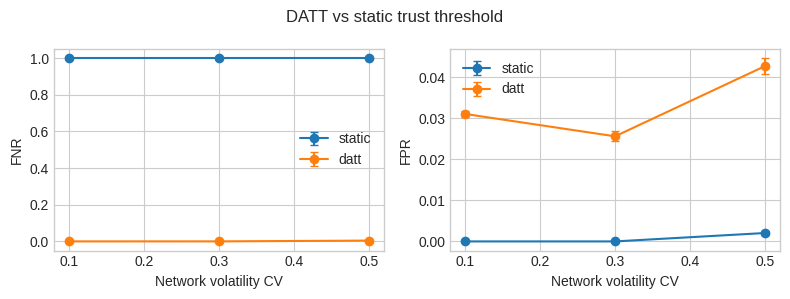

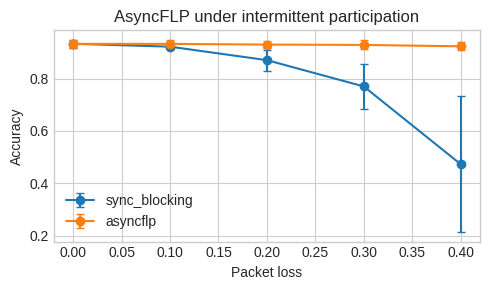

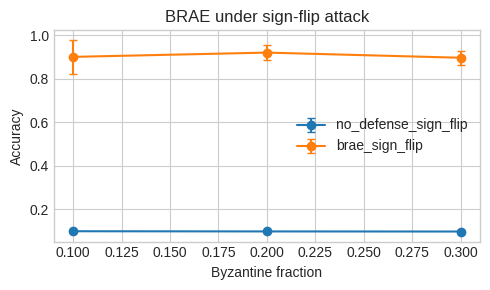

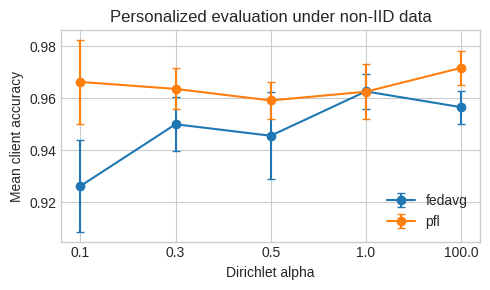

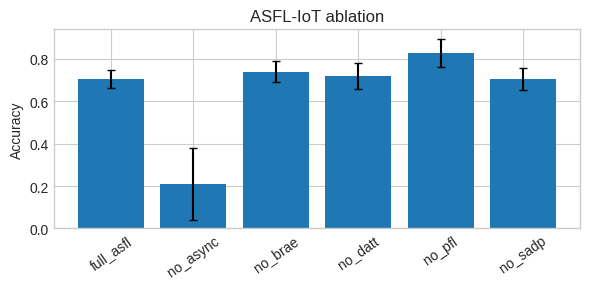

Figures saved to: /kaggle/working/asfl_iot_results/figures


In [23]:
plt.style.use("seaborn-v0_8-whitegrid")

# Trust FNR/FPR
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
for metric, ax in [("fnr", axes[0]), ("fpr", axes[1])]:
    for method in trust_df["method"].unique():
        sub = trust_df[trust_df["method"] == method]
        g = sub.groupby("cv")[metric].agg(["mean", "std"]).reset_index()
        ax.errorbar(g["cv"], g["mean"], yerr=g["std"], marker="o", capsize=3, label=method)
    ax.set_xlabel("Network volatility CV")
    ax.set_ylabel(metric.upper())
    ax.legend()
fig.suptitle("DATT vs static trust threshold")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/trust_fnr_fpr_vs_cv.pdf")
plt.show()

# Async under packet loss
fig, ax = plt.subplots(figsize=(5, 3))
for method in async_df["method"].unique():
    sub = async_df[async_df["method"] == method]
    g = sub.groupby("packet_loss")["accuracy"].agg(["mean", "std"]).reset_index()
    ax.errorbar(g["packet_loss"], g["mean"], yerr=g["std"], marker="o", capsize=3, label=method)
ax.set_xlabel("Packet loss")
ax.set_ylabel("Accuracy")
ax.set_title("AsyncFLP under intermittent participation")
ax.legend()
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/async_packet_loss_accuracy.pdf")
plt.show()

# Byzantine accuracy
fig, ax = plt.subplots(figsize=(5, 3))
tmp = byz_df[byz_df["method"].str.contains("sign_flip")]
for method in tmp["method"].unique():
    sub = tmp[tmp["method"] == method]
    g = sub.groupby("byz_frac")["accuracy"].agg(["mean", "std"]).reset_index()
    ax.errorbar(g["byz_frac"], g["mean"], yerr=g["std"], marker="o", capsize=3, label=method)
ax.set_xlabel("Byzantine fraction")
ax.set_ylabel("Accuracy")
ax.set_title("BRAE under sign-flip attack")
ax.legend()
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/byzantine_accuracy.pdf")
plt.show()

# PFL alpha sweep
fig, ax = plt.subplots(figsize=(5, 3))
for method in pfl_df["method"].unique():
    sub = pfl_df[pfl_df["method"] == method]
    g = sub.groupby("alpha")["mean_client_accuracy"].agg(["mean", "std"]).reset_index()
    ax.errorbar(g["alpha"].astype(str), g["mean"], yerr=g["std"], marker="o", capsize=3, label=method)
ax.set_xlabel("Dirichlet alpha")
ax.set_ylabel("Mean client accuracy")
ax.set_title("Personalized evaluation under non-IID data")
ax.legend()
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/pfl_alpha_sweep.pdf")
plt.show()

# Ablation
fig, ax = plt.subplots(figsize=(6, 3))
g = ablation_df.groupby("method")["accuracy"].agg(["mean", "std"]).reset_index()
ax.bar(g["method"], g["mean"], yerr=g["std"], capsize=3)
ax.set_ylabel("Accuracy")
ax.set_title("ASFL-IoT ablation")
ax.tick_params(axis="x", rotation=35)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/ablation_accuracy.pdf")
plt.show()

print("Figures saved to:", FIG_DIR)

In [24]:
# Runtime and reproducibility metadata
runtime_rows = []
for name, df in [
    ("async", async_df),
    ("byzantine", byz_df),
    ("privacy", dp_df),
    ("ablation", ablation_df),
    ("iot", iot_df),
]:
    runtime_rows.append({
        "experiment": name,
        "rows": len(df),
        "mean_final_elapsed_sec": df["elapsed_sec"].mean() if "elapsed_sec" in df else np.nan,
        "seeds": str(CONFIG["seeds"]),
        "rounds": CONFIG["rounds"],
        "clients": CONFIG["num_clients"],
    })

runtime_df = pd.DataFrame(runtime_rows)
runtime_df.to_csv(f"{OUT_DIR}/runtime_summary.csv", index=False)
display(runtime_df)

,experiment,rows,mean_final_elapsed_sec,seeds,rounds,clients
0,async,50,2.184862,"[1, 7, 21, 42, 100]",20,10
1,byzantine,90,3.186458,"[1, 7, 21, 42, 100]",20,10
2,privacy,15,3.176934,"[1, 7, 21, 42, 100]",20,10
3,ablation,30,1.806140,"[1, 7, 21, 42, 100]",20,10
4,iot,10,5.141701,"[1, 7, 21, 42, 100]",20,10


In [27]:
import shutil
zip_path = "/kaggle/working/asfl_iot_results.zip"
shutil.make_archive(zip_path.replace(".zip", ""), "zip", OUT_DIR)

print("Saved ZIP:", zip_path)
print("Files:")
for root, dirs, files in os.walk(OUT_DIR):
    for file in sorted(files):
        print(os.path.join(root, file))

Saved ZIP: /kaggle/working/asfl_iot_results.zip
Files:
/kaggle/working/asfl_iot_results/ablation_results.csv
/kaggle/working/asfl_iot_results/ablation_summary.csv
/kaggle/working/asfl_iot_results/async_results.csv
/kaggle/working/asfl_iot_results/async_summary.csv
/kaggle/working/asfl_iot_results/byzantine_results.csv
/kaggle/working/asfl_iot_results/byzantine_summary.csv
/kaggle/working/asfl_iot_results/config.json
/kaggle/working/asfl_iot_results/generalization_raw.csv
/kaggle/working/asfl_iot_results/generalization_summary.csv
/kaggle/working/asfl_iot_results/iot_results.csv
/kaggle/working/asfl_iot_results/iot_summary.csv
/kaggle/working/asfl_iot_results/paper_key_results.csv
/kaggle/working/asfl_iot_results/pfl_client_level_results.csv
/kaggle/working/asfl_iot_results/pfl_results.csv
/kaggle/working/asfl_iot_results/pfl_summary.csv
/kaggle/working/asfl_iot_results/privacy_results.csv
/kaggle/working/asfl_iot_results/privacy_summary.csv
/kaggle/working/asfl_iot_results/runtime_summ